In [3]:
import os
import tifffile
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [4]:
# -----------------------------------------------------------------------------
# BLOCK 4.2: Artificial Dot Injection Functions
# -----------------------------------------------------------------------------
def inject_artificial_points(image, num_points=5, radius=10, intensity_scale=0.01, return_points=False):
    height, width = image.shape
    point_image = np.copy(image)
    points = []

    for _ in range(num_points):
        x, y = np.random.randint(0, width), np.random.randint(0, height)
        points.append([x, y])

        mean_intensity = np.mean(image)
        point_intensity = mean_intensity + intensity_scale * mean_intensity

        point_image = cv2.circle(point_image, (x,y), radius=radius, color=(0, 0, 0), thickness=-1)

    if return_points:
        return point_image, np.array(points)
    else:
        return point_image

def detect_points(image):
    thresh = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    thresh = thresh.astype('uint8')

    # Filter out large non-connecting objects
    cnts = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = cnts[0] if len(cnts) == 2 else cnts[1]
    for c in cnts:
        area = cv2.contourArea(c)
        if area > 5:
            cv2.drawContours(thresh,[c],0,0,-1)

    cnts = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = cnts[0] if len(cnts) == 2 else cnts[1]

    for c in cnts:
        ((x, y), r) = cv2.minEnclosingCircle(c)
        print(x, y, r)

    return thresh

In [5]:
# -----------------------------------------------------------------------------
# BLOCK 10: Single Image Processing Pipeline (For Debugging/Visualization)
# -----------------------------------------------------------------------------
def process_and_visualize_single_image():
    input_folder = config["DATA"]["input_folder"]
    image_path = os.path.join(input_folder, "sample_1_cs_4_2/0049.tiff")  # Example image path

    # Load the original image.
    original_image = tifffile.imread(image_path)

    # Inject artificial points
    original_with_lines = inject_artificial_points(
        original_image,
        radius=1,
        num_points=5,
    )

    thresh = detect_points(original_with_lines)

    plt.figure(figsize=(10, 8))
    plt.imshow(thresh, cmap="gray")
    plt.axis('off')
    plt.show()

process_and_visualize_single_image()

669.0 824.0 1.000100016593933
670.0 693.0 1.000100016593933
822.0 382.0 1.000100016593933
539.0 149.0 1.000100016593933


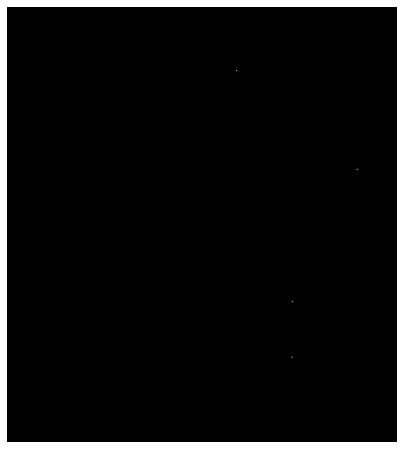

In [5]:
import os
import cv2
import numpy as np
import tifffile
import matplotlib.pyplot as plt

In [73]:
# -----------------------------------------------------------------------------
# Configuration
# -----------------------------------------------------------------------------
config = {
    "PREPROCESSING": {
        "sigma": 1,
        "clip_limit": 0.01,
    },
    "ARTIFICIAL_INJECTION": {
        "num_lines": 5,
        "thickness": 3,
        "intensity_scale": 0.01,
    },
    "DATA": {
        "input_folder": "",      
        #"data_dir": "/home/ws/uuwhk/PaleoDM/sample_1_cs_4_2",
        "data_dir": "/home/ws/uuwhk/PaleoDM/sample_2_with_mock_data",
        #"data_dir": "/home/ws/uuwhk/PaleoDM/sample_4_small",
        "img_shape": 128,
    }
}

In [74]:
# -----------------------------------------------------------------------------
# Helper Function: Dot Detection Returning Coordinates
# -----------------------------------------------------------------------------
def detect_dot_coords(image):
    """
    Process the input grayscale image to detect dot-like features.
    Returns the thresholded image and a list of (x, y) coordinates for each detected dot.
    """
    # Apply thresholding (binary inverse with Otsu)
    thresh = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    thresh = thresh.astype('uint8')
    
    # Find contours
    cnts = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = cnts[0] if len(cnts) == 2 else cnts[1]
    
    # Filter out large contours that are unlikely to be small dots
    valid_contours = []
    for c in cnts:
        area = cv2.contourArea(c)
        # Adjust threshold as needed; here we assume dots have area < 50
        if area < 50:
            valid_contours.append(c)
        else:
            cv2.drawContours(thresh, [c], 0, 0, -1)
    
    # Extract coordinates from contours
    coords = []
    for c in valid_contours:
        ((x, y), r) = cv2.minEnclosingCircle(c)
        coords.append((x, y))
    
    return thresh, coords

def euclidean_distance(p1, p2):
    """Calculate the Euclidean distance between two points p1 and p2."""
    return np.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

def correlate_dots(prev_coord, current_coords, tolerance=5):
    """
    Check if any coordinate in current_coords is within the given tolerance
    of the prev_coord.
    
    Returns:
        (found: bool, matched_coord: tuple or None)
    """
    for coord in current_coords:
        if euclidean_distance(prev_coord, coord) <= tolerance:
            return True, coord
    return False, None

In [75]:
# -----------------------------------------------------------------------------
# Main Function: Process Consecutive Frames for 3D Track Detection
# -----------------------------------------------------------------------------
def process_frames_for_tracks(start_frame=5, end_frame=100, tolerance=5, max_missing=2):
    """
    Process consecutive TIFF files and check for correlated dot detections.
    
    Returns:
        track (list): List of tuples (frame_number, coordinate) indicating the detected track.
    """
    data_dir = config["DATA"]["data_dir"]
    track = []  # Holds (frame_number, coordinate) for the track
    missing_count = 0
    
    for frame_number in range(start_frame, end_frame + 1):
        #file_name = f"{frame_number:04d}.tiff"
        file_name = f"sample_{frame_number:04d}.tiff"
        file_path = os.path.join(data_dir, file_name)
        
        if not os.path.exists(file_path):
            print(f"File {file_path} does not exist, skipping.")
            continue
        
        # Read the image (assumed grayscale)
        image = tifffile.imread(file_path)
        thresh, coords = detect_dot_coords(image)
        print(f"Frame {frame_number}: Detected dots: {coords}")
        
        if len(coords) == 0:
            missing_count += 1
            print(f"No dots detected in frame {frame_number}. Missing count: {missing_count}")
            if missing_count >= max_missing:
                print("Maximum consecutive missing frames reached. Ending track detection.")
                break
            continue
        else:
            missing_count = 0  # reset
        
        # If this is the first detection, initialize the track with the first dot
        if len(track) == 0:
            track.append((frame_number, coords[0]))
        else:
            last_frame, last_coord = track[-1]
            found, matched_coord = correlate_dots(last_coord, coords, tolerance)
            if found:
                track.append((frame_number, matched_coord))
            else:
                missing_count += 1
                if missing_count >= max_missing:
                    print("Consecutive frames missing correlation. Ending track.")
                    break
    return track

Frame 5: Detected dots: [(915.0, 511.5)]
Frame 6: Detected dots: [(85.0, 588.0), (915.0, 511.0)]
Frame 7: Detected dots: [(85.0, 589.0), (915.0, 510.0)]
Frame 8: Detected dots: [(168.0, 709.0), (915.0, 510.0)]
Frame 9: Detected dots: [(915.0, 519.5), (915.0, 509.5), (915.0, 496.0)]
Frame 10: Detected dots: [(87.0, 590.0), (915.0, 519.5), (915.0, 510.0), (915.0, 496.0)]
Frame 11: Detected dots: [(88.0, 591.0), (915.0, 520.0), (915.0, 504.5), (915.0, 496.0)]
Frame 12: Detected dots: [(169.0, 708.0), (88.0, 591.0), (915.0, 520.0), (915.0, 504.5), (915.0, 496.0)]
Frame 13: Detected dots: [(89.0, 591.0), (915.0, 520.0), (915.0, 504.5), (915.0, 495.5)]
Frame 14: Detected dots: [(915.0, 504.0), (915.0, 495.5)]
Frame 15: Detected dots: [(915.0, 503.0)]
Frame 16: Detected dots: [(170.0, 708.0), (915.0, 508.0), (915.0, 497.0)]
Frame 17: Detected dots: [(170.0, 708.0), (915.0, 506.0), (915.0, 494.5)]
Frame 18: Detected dots: [(915.0, 504.0), (915.0, 494.0)]
Frame 19: Detected dots: [(170.0, 707.0

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


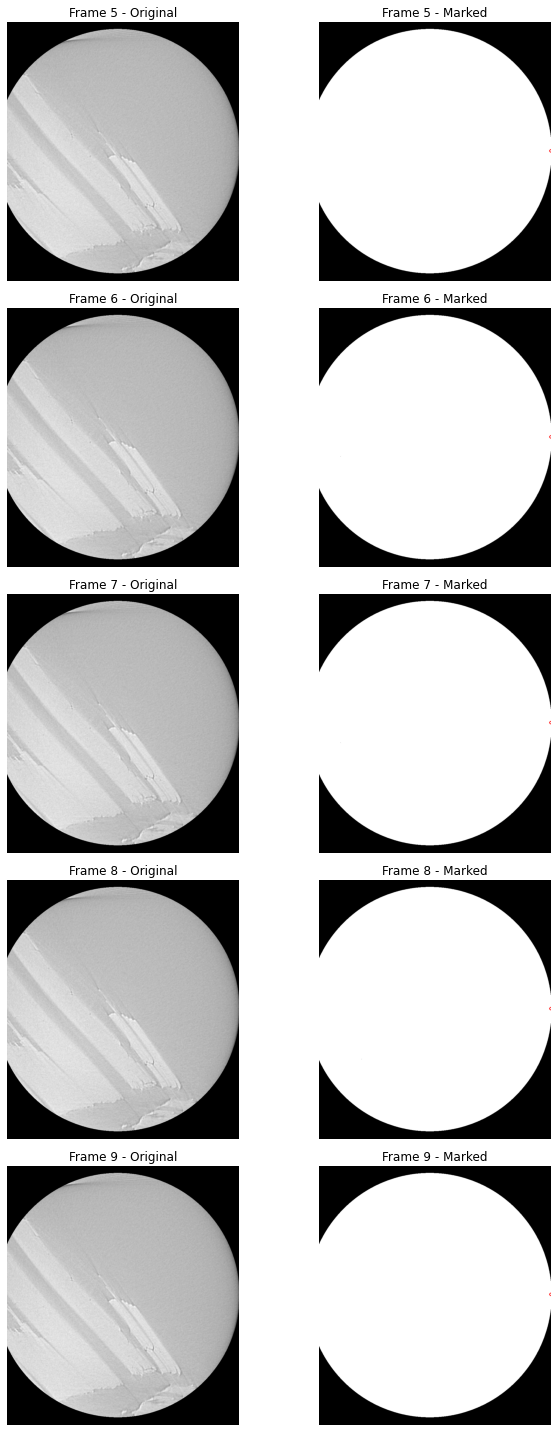

In [76]:
# -----------------------------------------------------------------------------
# Example Run: Process a Sequence of Frames
# -----------------------------------------------------------------------------
if __name__ == "__main__":
    detected_track = process_frames_for_tracks(start_frame=5, end_frame=20, tolerance=5, max_missing=2)
    if detected_track:
        print("\nDetected Track:")
        for frame, coord in detected_track:
            print(f"Frame {frame}: Coordinate {coord}")
    else:
        print("No correlated track detected.")

def visualize_track_comparisons(track, num_comparisons=5, marker_radius=5, marker_color=(0, 0, 255), marker_thickness=2):
    """
    Visualize the original TIFF images alongside marked versions for the detected track points.
    """
    data_dir = config["DATA"]["data_dir"]
    n = min(num_comparisons, len(track))
    
    fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(10, 4*n))
    
    if n == 1:
        axes = np.array([axes])
    
    for idx in range(n):
        frame_number, coord = track[idx]
        #file_name = f"{frame_number:04d}.tiff"
        file_name = f"sample_{frame_number:04d}.tiff"
        file_path = os.path.join(data_dir, file_name)
        
        # Load the original TIFF image
        image = tifffile.imread(file_path)
        
        # Create a copy to mark the detected dot
        if len(image.shape) == 2:
            marked_image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
        else:
            marked_image = image.copy()
        
        x, y = int(coord[0]), int(coord[1])
        cv2.circle(marked_image, (x, y), radius=marker_radius, color=marker_color, thickness=marker_thickness)
        
        axes[idx, 0].imshow(image, cmap='gray')
        axes[idx, 0].set_title(f"Frame {frame_number} - Original")
        axes[idx, 0].axis('off')
        
        axes[idx, 1].imshow(cv2.cvtColor(marked_image, cv2.COLOR_BGR2RGB))
        axes[idx, 1].set_title(f"Frame {frame_number} - Marked")
        axes[idx, 1].axis('off')
    
    plt.tight_layout()
    plt.show()

# Example call (assuming `detected_track` was produced earlier):
if detected_track:
    visualize_track_comparisons(detected_track, num_comparisons=5)
else:
    print("No track to visualize.")

In [77]:
from mpl_toolkits.mplot3d import Axes3D  # Needed for 3D projection
import matplotlib as mpl

def plot_3d_dots(start_frame=5, end_frame=796):
    """
    Loops through frames from start_frame to end_frame, detects dot coordinates, 
    and creates a 3D scatter plot:
       x-axis = dot's x coordinate
       y-axis = dot's y coordinate
       z-axis = frame number 

    - Excludes points with x == 915.0
    - Color-codes the dots by their frame number (Z) via a continuous colorbar
    - Includes a legend entry labeling the scatter points
    - No lines are drawn between dots
    """
    data_dir = config["DATA"]["data_dir"]
    
    all_x = []
    all_y = []
    all_z = []
    
    for frame_number in range(start_frame, end_frame + 1):
        file_name = f"sample_{frame_number:04d}.tiff"
        file_path = os.path.join(data_dir, file_name)
        
        if not os.path.exists(file_path):
            print(f"File {file_path} does not exist; skipping.")
            continue
        
        # Read and detect dots
        image = tifffile.imread(file_path)
        _, coords = detect_dot_coords(image)
        
        # Exclude corner-edge detection where x == 915.0
        for (x, y) in coords:
            if x != 915.0:
                all_x.append(x)
                all_y.append(y)
                all_z.append(frame_number)
    
    # Create the 3D scatter plot
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')

    # Use the z-coordinates (frame_number) as the color values
    sc = ax.scatter(all_x, all_y, all_z, c=all_z, cmap='plasma', marker='o', 
                    label='Detected Interaction Points')

    # Create a colorbar to show the mapping of frame number to color
    cb = plt.colorbar(sc, ax=ax, fraction=0.02, pad=0.1)
    cb.set_label('Frame Number (Z)')

    # Add a legend for the scatter points
    ax.legend(
        loc='upper right',
        bbox_to_anchor=(1.2, 1.0))

    # Axis labels and title
    ax.set_xlabel('X Coordinate')
    ax.set_ylabel('Y Coordinate')
    ax.set_zlabel('Frame Number (Z)')
    ax.set_title("3D Dot Coordinates\n(Excluding x=915.0, Color-coded by Frame)")
    
    plt.savefig("reconst_large.png", dpi=300, bbox_inches='tight')

    # Optionally set a viewing angle if desired:
    #ax.view_init(elev=90, azim=90)

    plt.show()

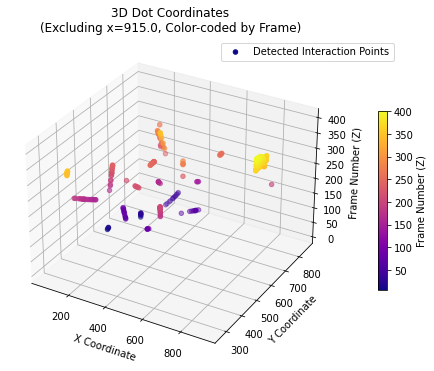

In [78]:
# -----------------------------------------------------------------------------
# CALL THE 3D PLOTTING FUNCTION
# -----------------------------------------------------------------------------
plot_3d_dots(start_frame=5, end_frame=789)